Libraries from the lab file

In [1]:
import torch
from torch import nn
from sklearn import model_selection
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from IPython import display
import numpy as np

import typing
%matplotlib inline

[HAMI-core Msg(113:140185213173056:libvgpu.c:839)]: Initializing.....


<b>Part 0 — Setup: data and computing (do this first, then never change it)</b>

<b>0.3 Suggested repository layout </b>
ecs708-fashion-mnist/  
&nbsp;&nbsp;&nbsp;&nbsp;|-- README.md # install, data download, commands, hardware, runtimes  
&nbsp;&nbsp;&nbsp;&nbsp;|-- requirements.txt # pinned versions  
&nbsp;&nbsp;&nbsp;&nbsp;|-- configs/ # one config file per experiment ID  
&nbsp;&nbsp;&nbsp;&nbsp;|-- splits/ # saved split and subset indices (+ seeds)  
&nbsp;&nbsp;&nbsp;&nbsp;|-- src/ # data, models, training, evaluation, clustering code  
&nbsp;&nbsp;&nbsp;&nbsp;|-- results/ # logs, metrics tables, experiment register  
&nbsp;&nbsp;&nbsp;&nbsp;|-- figures/ # generated Notebook figures (+ script mapping)  
&nbsp;&nbsp;&nbsp;&nbsp;|-- scripts/ # e.g. smoke_run.sh, make_figures.py

In [13]:
from pathlib import Path
for folder in ["configs", "splits", "src", "results", "figures", "scripts"]:
    Path(folder).mkdir(exist_ok=True)

<b>0.1 Fixed data partitions</b>

1. <b>Dataset</b>: Fashion-MNIST, 28×28 greyscale, 10 classes (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot); 60,000 official train, 10,000 official test.

In [2]:
# using PyTorch to get the training and test datasets
from torchvision.datasets import FashionMNIST
train_dataset = FashionMNIST(root="data",train=True,download=True,)

In [6]:
train_dataset

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train

In [3]:
# Extracting the contents from this downloaded dataset above
x_data = train_dataset.data
y_target = train_dataset.targets
print(x_data.shape)
print(y_target.shape)

torch.Size([60000, 28, 28])
torch.Size([60000])


In [4]:
#Another way of doing this from the google search, this apparently gives numpy arrays directly
images = train_dataset.data.numpy()
classes = train_dataset.targets.numpy()
class_names = train_dataset.classes

.  

<b>Understanding the data</b>


In [15]:
print("total samples", len(train_dataset))
print("images, i.e., X/data", images.shape)
print("the labels for them, i.e., Y/target", classes.shape)
print("the 10 classes:", class_names)

total samples 60000
images, i.e., X/data (60000, 28, 28)
the labels for them, i.e., Y/target (60000,)
the 10 classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [16]:
# Check the distribution of images across the classes
unique_labels, counts = torch.unique(y_target, return_counts=True)
for label_index, count in zip(unique_labels, counts):
    class_name = class_names[label_index.item()]
    print(f"{class_name}: {count.item()} images")

T-shirt/top: 6000 images
Trouser: 6000 images
Pullover: 6000 images
Dress: 6000 images
Coat: 6000 images
Sandal: 6000 images
Shirt: 6000 images
Sneaker: 6000 images
Bag: 6000 images
Ankle boot: 6000 images


In [10]:
# Grab the 10th sample from the dataset
img, cls = train_dataset[9]
print(f"Image datatype: {type(img)}")
print(f"Class datatype: {type(cls)}")
print(f"Class: {cls}: Class name: {class_names[cls]}")
print("image range:", images.min(), "to", images.max())

Image datatype: <class 'PIL.Image.Image'>
Class datatype: <class 'int'>
Class: 5: Class name: Sandal
image range: 0 to 255


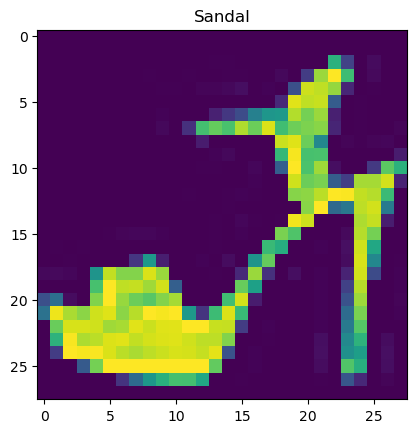

In [20]:
#how does a image look like?
plt.imshow(x_data[9])
plt.title(class_names[y_target[9]])
plt.show()

2. <b>Split</b> the official training set, stratified and seeded: 50,000 train / 10,000 validation. Save the seed and indices. Here, stratification means splitting or sampling data so that each resulting partition or subset preserves approximately the same class proportions as the source data. This is done by randomly selecting examples within each class, reducing accidental differences in class composition between partitions. For example, if each of the ten classes represents 10% of the source data, a stratified 10,000-image subset contains approximately 1,000 images per class. Stratification preserves existing proportions; it does not make an imbalanced dataset balanced. Use a fixed random seed and save the selected indices so that your splits are reproducible. For clustering, labels may be used to construct these subsets, but must not be used to compute distances, fit centroids or assign clusters. See the scikit-learn guide to stratified splitting for further explanation.
3. <b>Test set</b>: untouched until the final evaluation.
4. <b>CPU-friendly option (allowed, no penalty)</b>: fit models on a fixed stratified 10,000-image subset of the training partition; keep the same validation and test sets. Using the full 50k gives no inherent marking advantage.

In [6]:
#from sklearn.model_selection import StratifiedShuffleSplit
#import numpy as np
#TEST_SEED = 42
#the stratified splitter per documentation 
#strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=10000, random_state=TEST_SEED)
#targets = np.array(train_dataset.targets)
#train_index, val_index = next(strat_shuff_split.split(np.zeros(len(targets)), targets))

In [5]:
from sklearn.model_selection import train_test_split

TEST_SEED = 42
FIT_SEED = 43

all_index = np.arange(len(classes))
train_index, val_index = train_test_split(
    all_index,train_size=50_000,test_size=10_000,random_state=TEST_SEED,stratify=classes,)
fit_index, _ = train_test_split(
    train_index,train_size=10_000,random_state=FIT_SEED,stratify=classes[train_index],)

In [6]:
import json
split_config = {
    "test_seed": TEST_SEED,
    "fit_seed": FIT_SEED,
    "train_index": train_index.tolist(),
    "val_index": val_index.tolist(),
    "fit_index":fit_index.tolist()
}
with open("configs/fashion_mnist_split_config.json", "w") as f:
    json.dump(split_config, f)

In [7]:
#check everything works as planned?!
print(f"training set size: {len(train_index)}")
print(f"validation set size: {len(val_index)}")
print(f"fit set size: {len(fit_index)}")

class_counts = pd.DataFrame(
    {
        "training set": np.bincount(classes[train_index]),
        "fitting subset": np.bincount(classes[fit_index]),
        "testing set": np.bincount(classes[val_index]),
    },
    index=pd.Index(class_names, name="Class"),
)
print(class_counts.to_string())


training set size: 50000
validation set size: 10000
fit set size: 10000
             training set  fitting subset  testing set
Class                                                 
T-shirt/top          5000            1000         1000
Trouser              5000            1000         1000
Pullover             5000            1000         1000
Dress                5000            1000         1000
Coat                 5000            1000         1000
Sandal               5000            1000         1000
Shirt                5000            1000         1000
Sneaker              5000            1000         1000
Bag                  5000            1000         1000
Ankle boot           5000            1000         1000


In [8]:
#image values are converted to float32 and divided by 255 to scale it from 0 to 
# processing the fitting subset of the training this
X_fit = images[fit_index].astype(np.float32).reshape(len(fit_index), -1) / 255.0
y_fit = classes[fit_index]

# processing the testing subset
X_val = images[val_index].astype(np.float32).reshape(len(val_index), -1) / 255.0
y_val = classes[val_index]

In [34]:
#checking if the standardization worked
print("fitting images:", X_fit.shape, X_fit.dtype)
print("fitting classes:", y_fit.shape, y_fit.dtype)
print("validation images:", X_val.shape, X_val.dtype)
print("validation classes:", y_val.shape, y_val.dtype)
print("fitting pixel range:", X_fit.min(), "to", X_fit.max())

fitting images: (10000, 784) float32
fitting classes: (10000,) int64
validation images: (10000, 784) float32
validation classes: (10000,) int64
fitting pixel range: 0.0 to 1.0


5. Clustering / feature-extraction subsets: fixed ≈3,000 train, 1,000 validation and 1,000 test images. Use exactly the same images for every representation.

In [11]:
CLUSTER_SEED = 44
cluster_train_index, _ = train_test_split(fit_index, train_size=3_000,
    random_state=CLUSTER_SEED,stratify=classes[fit_index])
cluster_val_index, _ = train_test_split(val_index, train_size=1_000,
    random_state=CLUSTER_SEED,stratify=classes[val_index])

# Taking labels from test set only to create the required stratified test subset.
# This is allowed per the coursework instructions
test_dataset = FashionMNIST(root="data",train=False,download=True,)
test_classes = test_dataset.targets.numpy()
test_index = np.arange(len(test_classes))

cluster_test_index, _ = train_test_split(test_index, train_size=1_000,
    random_state=CLUSTER_SEED,stratify=test_classes[test_index])

In [36]:
# write this as well to a seperate config file?!
cluster_config = {
    "cluster_seed": CLUSTER_SEED,
    "train_index": cluster_train_index.tolist(),
    "val_index": cluster_val_index.tolist(),
    "test_index":cluster_test_index.tolist()
}
with open("configs/fashion_mnist_cluster_config.json", "w") as f:
    json.dump(cluster_config, f)

In [37]:
print(f"Clustering train size: {len(cluster_train_index)}")      # Outputs: 3000
print(f"Clustering val size:   {len(cluster_val_index)}")        # Outputs: 1000
print(f"Clustering test size:  {len(cluster_test_index)}")  
cluster_summary = pd.DataFrame({
    "Subset": ["Training", "Validation", "Test"],
    "Images": [len(cluster_train_index),len(cluster_val_index),len(cluster_test_index),],
    "Images per class": [300, 100, 100],})

#print(cluster_summary.to_string())
print(cluster_summary.to_string(index=False))

Clustering train size: 3000
Clustering val size:   1000
Clustering test size:  1000
    Subset  Images  Images per class
  Training    3000               300
Validation    1000               100
      Test    1000               100


.  
*** <b>End of Part 0 *** </b>

In [55]:
#R3. Keep an experiment register. Per experiment: ID, question, hypothesis, changed variable, fixed conditions, split, seed, configuration, metric, result, output path. Keep informative failures.
#note: not sure if its needed for Part 0, but creating one anyway as a template for later use
from pathlib import Path
register_path = Path("results/experiment_register.csv")
exp_data_setup = {
    "id": "P0-DATA_SETUP-01",
    "question": "Are the data partitions stratified, seeded and saved so they are reproducible?",
    "hypothesis": "Class proportions are preserved by stratification",
    "changed_variable": "Nothing so far",
    "fixed_conditions": "Fashion-MNIST dataset downloaded",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": " 28 x 28 float32 pixels / 0-255, flattened to 784 features",
    "metric": "set sizes, class counts, index overlap",
    "result": (
        f"Train/validation overlap = {np.intersect1d(train_index, val_index).size}; "
        f"clustering sizes={len(cluster_train_index)}/{len(cluster_val_index)}/{len(cluster_test_index)}"
    ),
    "output_path": (
        "configs/fashion_mnist_split_config.json; configs/cashion_mnist_cluster_config.json; "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_data_setup])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

.  
<b>Part 1 — Classical classification</b>

1.1 <b>Models. </b>Choose at least two classifiers or configurations from the methods taught in the module. Justify your choice for this data.  
1.2 <b>Metrics.</b> Notebook overall accuracy and a class-level view of performance, with enough information for readers to interpret any proportions.


In [9]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [14]:
# trying some classifiers first to learn how they all differ - this is for Logistic Regression
# To-do: I have to choose two eventually and justity
from sklearn.linear_model import LogisticRegression
register_path = Path("results/experiment_register.csv")
logreg = LogisticRegression(C=1.0, solver="lbfgs", max_iter=500)
logreg.fit(X_fit, y_fit)
fit_predict_logreg = logreg.predict(X_fit)
val_predict_logreg = logreg.predict(X_val)

print(f"Logistic Regression: fitting accuracy: {accuracy_score(y_fit, fit_predict_logreg):.2%}")
print(f"Logistic Regression: validation accuracy: {accuracy_score(y_val, val_predict_logreg):.2%}")

cm = confusion_matrix(y_val, val_predict_logreg, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Logistic Rregression: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_lr = pd.DataFrame(classification_report(y_val, val_predict_logreg,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_lr = report_lr.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_lr["support"] = class_level_lr["support"].astype(int)
class_level_lr.to_csv("results/part1_logreg_validation_by_class.csv")
print(class_level_lr.round(3).to_string())

exp_part1_logreg = {
    "id": "P1-LOGREG-01",
    "question": "Is Logistic Regression the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "C=1.0, solver=lbfgs, max_iter=500",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "C=1.0, solver=lbfgs, max_iter=500",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_logreg):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_logreg):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_logreg_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Logistic Regression: fitting accuracy: 92.46%
Logistic Regression: validation accuracy: 84.08%
Logistic Rregression: Lowest recall = 59.6% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.784   0.813     0.798     1000
Trouser          0.968   0.961     0.964     1000
Pullover         0.731   0.743     0.737     1000
Dress            0.864   0.829     0.846     1000
Coat             0.727   0.741     0.734     1000
Sandal           0.931   0.924     0.928     1000
Shirt            0.616   0.596     0.606     1000
Sneaker          0.908   0.909     0.909     1000
Bag              0.947   0.940     0.943     1000
Ankle boot       0.933   0.952     0.943     1000


In [15]:
print(class_level_lr.sort_values("recall")[["recall", "support"]].to_string())

             recall  support
Shirt         0.596     1000
Coat          0.741     1000
Pullover      0.743     1000
T-shirt/top   0.813     1000
Dress         0.829     1000
Sneaker       0.909     1000
Sandal        0.924     1000
Bag           0.940     1000
Ankle boot    0.952     1000
Trouser       0.961     1000


.  
** Observation notes **  
 - Shirt was the hardest class and Trouser was the easiest on the validation set
 - Based on stratification, Shirts included 10% of the validation images but accounted for 25.4% (404) of the model’s 1592 errors
 - Coat and Pullover were the next hardest classes, with 741 and 743 correct predictions

In [19]:
#Analysis: what did the model predict incorrectly for those 404 missed shirts?
shirt_id = class_names.index("Shirt")
missed_shirts = (y_val == shirt_id) & (val_predict_logreg != shirt_id)

wrong_labels = [class_names[pred] for pred in val_predict_logreg[missed_shirts]]
print(pd.Series(wrong_labels).value_counts().to_string())

T-shirt/top    144
Pullover       109
Coat           103
Dress           30
Bag             16
Trouser          2


In [21]:
# trying some classifiers first to learn how they all differ - this is for SVM
# To-do: I have to choose two eventually and justity
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_fit, y_fit)
fit_predict_svm = svm.predict(X_fit)
val_predict_svm = svm.predict(X_val)

print(f"SVM: fit accuracy: {accuracy_score(y_fit, fit_predict_svm):.2%}")
print(f"SVM: validation accuracy: {accuracy_score(y_val, val_predict_svm):.2%}")

cm = confusion_matrix(y_val, val_predict_svm, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"SVM: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_svm = pd.DataFrame(classification_report(y_val, val_predict_svm,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_svm = report_svm.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_svm["support"] = class_level_svm["support"].astype(int)
class_level_svm.to_csv("results/part1_svm_validation_by_class.csv")
print(class_level_svm.round(3).to_string())

exp_part1_svm = {
    "id": "P1-SVM-01",
    "question": "Is Support Vector Machine Classifier the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "kernel='rbf', C=1.0, gamma='scale', random_state=42",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "kernel='rbf', C=1.0, gamma='scale', random_state=42",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_svm):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_svm):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_svm_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_svm])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


SVM: fit accuracy: 89.89%
SVM: validation accuracy: 86.74%
SVM: Lowest recall = 62.6% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.800   0.859     0.828     1000
Trouser          0.993   0.960     0.976     1000
Pullover         0.766   0.792     0.779     1000
Dress            0.854   0.870     0.862     1000
Coat             0.793   0.799     0.796     1000
Sandal           0.942   0.940     0.941     1000
Shirt            0.705   0.626     0.663     1000
Sneaker          0.928   0.910     0.919     1000
Bag              0.953   0.958     0.956     1000
Ankle boot       0.935   0.960     0.947     1000


In [22]:
# trying some classifiers first to learn how they all differ - this is for Random Forest
# To-do: I have to choose two eventually and justity
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_fit, y_fit)
fit_predict_rf = rf.predict(X_fit)
val_predict_rf = rf.predict(X_val)

print(f"Random Forest: fit accuracy: {accuracy_score(y_fit, fit_predict_rf):.2%}")
print(f"Random Forest: validation accuracy: {accuracy_score(y_val, val_predict_rf):.2%}")

cm = confusion_matrix(y_val, val_predict_rf, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Random Forest: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_rf = pd.DataFrame(classification_report(y_val, val_predict_rf,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_rf = report_rf.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_rf["support"] = class_level_rf["support"].astype(int)
class_level_rf.to_csv("results/part1_rf_validation_by_class.csv")
print(class_level_rf.round(3).to_string())

exp_part1_rf = {
    "id": "P1-RF-01",
    "question": "Is Random Forest the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "n_estimators=100, random_state=42, n_jobs=-1",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "n_estimators=100, random_state=42, n_jobs=-1",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_rf):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_rf):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_rf_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_rf])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Random Forest: fit accuracy: 100.00%
Random Forest: validation accuracy: 86.10%
Random Forest: Lowest recall = 56.7% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.803   0.855     0.828     1000
Trouser          0.991   0.960     0.975     1000
Pullover         0.722   0.790     0.755     1000
Dress            0.860   0.880     0.870     1000
Coat             0.749   0.780     0.764     1000
Sandal           0.958   0.944     0.951     1000
Shirt            0.731   0.567     0.639     1000
Sneaker          0.927   0.911     0.919     1000
Bag              0.941   0.972     0.956     1000
Ankle boot       0.923   0.951     0.937     1000


In [28]:
# trying some classifiers first to learn how they all differ - this is for Decision Tree
# To-do: I have to choose two eventually and justity
from sklearn.tree import DecisionTreeClassifier

dectree = DecisionTreeClassifier(criterion="gini", max_depth=10,random_state=42,)
dectree.fit(X_fit, y_fit)
fit_predict_dectree = dectree.predict(X_fit)
val_predict_dectree = dectree.predict(X_val)

print(f"Decision Tree: fit accuracy: {accuracy_score(y_fit, fit_predict_dectree):.2%}")
print(f"Decision Tree: validation accuracy: {accuracy_score(y_val, val_predict_dectree):.2%}")

cm = confusion_matrix(y_val, val_predict_dectree, labels=range(len(class_names)))
recall = cm.diagonal() / cm.sum(axis=1)
hardest = recall.argmin()
print(f"Decision Tree: Lowest recall = {recall[hardest]:.1%} for {class_names[hardest]}")

report_dectree = pd.DataFrame(classification_report(y_val, val_predict_dectree,
        labels=range(len(class_names)),target_names=class_names, output_dict=True, zero_division=0,)).T

class_level_dectree = report_dectree.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
class_level_dectree["support"] = class_level_dectree["support"].astype(int)
class_level_dectree.to_csv("results/part1_dectree_validation_by_class.csv")
print(class_level_dectree.round(3).to_string())

exp_part1_dectree = {
    "id": "P1-DECTREE-01",
    "question": "Is Decision Tree the correct model for this dataset?",
    "hypothesis": "Highest accuracy, highest recall",
    "changed_variable": "criterion=gini, max_depth=10,random_state=42,",
    "fixed_conditions": "None",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "criterion=gini, max_depth=10,random_state=42,",
    "metric": "fit accuracy, validation accuracy, lowest recall",
    "result": (
        f"fit accuracy: {accuracy_score(y_fit, fit_predict_dectree):.2%}; "
        f"validation accuracy: {accuracy_score(y_val, val_predict_dectree):.2%}"
        f"lowest recall:{recall[hardest]:.1%} for {class_names[hardest]}"
    ),
    "output_path": (
        "results/part1_dectree_validation_by_class.csv "
    ),
}

register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_dectree])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


Decision Tree: fit accuracy: 87.37%
Decision Tree: validation accuracy: 77.82%
Decision Tree: Lowest recall = 45.1% for Shirt
             precision  recall  f1-score  support
T-shirt/top      0.778   0.768     0.773     1000
Trouser          0.953   0.939     0.946     1000
Pullover         0.649   0.653     0.651     1000
Dress            0.791   0.794     0.792     1000
Coat             0.588   0.729     0.651     1000
Sandal           0.887   0.848     0.867     1000
Shirt            0.545   0.451     0.494     1000
Sneaker          0.834   0.847     0.841     1000
Bag              0.897   0.875     0.886     1000
Ankle boot       0.875   0.878     0.876     1000


1.3 <b>Error analysis</b>. Inspect a small set of correct and incorrect predictions. Discuss easy and hard classes.
* Which classes does each model recognise most and least often?
* What do their mistakes look like on the same images?



In [50]:
#this is to compare all models to find mistakes that all of them make and see if there is a pattern
for model_name, predictions in [
    ("Logistic regression", val_predict_logreg),
    ("SVM",val_predict_svm),
    ("Random Forest", val_predict_rf),
    ("Decision tree", val_predict_dectree),]:
    cm = confusion_matrix(y_val, predictions, labels=range(len(class_names)))
    recall = cm.diagonal() / cm.sum(axis=1)
    hardest = recall.argmin()
    errors = cm[hardest].copy()
    errors[hardest] = 0
    confused_with = errors.argmax()
    print(f"{model_name}: From {cm[hardest].sum()} actual images of {class_names[hardest]}, {errors[confused_with]} were predicted as {class_names[confused_with]}.")


Logistic regression: recall = 59.6% for Shirt
Logistic regression: From 1000 actual images of Shirt, 144 were predicted as T-shirt/top.
SVM: recall = 62.6% for Shirt
SVM: From 1000 actual images of Shirt, 156 were predicted as T-shirt/top.
Random Forest: recall = 56.7% for Shirt
Random Forest: From 1000 actual images of Shirt, 166 were predicted as T-shirt/top.
Decision tree: recall = 45.1% for Shirt
Decision tree: From 1000 actual images of Shirt, 184 were predicted as Coat.


.  
*** Observations (more like questions to find answer) from the above experiments: ***
1. Training set accuracy for Random Forest is 100%. Is it overfiting? The short recall is low as well?
2. Decision tre has the lowest recall, lowest accuracy rate and struggles more with shirts, should we drop it?
3. All other models confused the shirt with t-shirt/top but decision tree confused with coat. It seems to identify the pattern correctly but strugggles on the brightness of the pixel?
4. Why does Shirt have the lowest recall while pullover and coat look the same?
5. Logistic regression had least mis-predictions of shirt but why is its recall is low compared to SVM?
6. Does highest recall (63.6%) alone is sufficient factor to pick SVM?

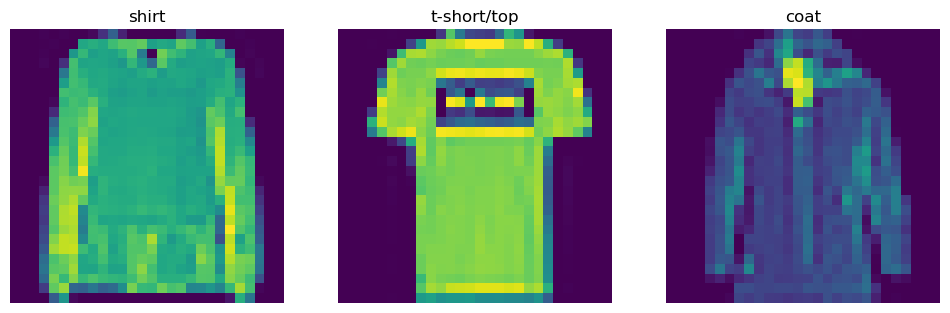

In [49]:
#Analysis: why are three of the classifers mostly strugging with short vs T-short/top?!!
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#for shirt
shirt_index = np.where(labels == 6)[0][0]
shirt_img = images[shirt_index]
axes[0].imshow(shirt_img)
axes[0].set_title("shirt")
axes[0].axis('off')

# for t-shirt/top
t_shirt_index = np.where(labels == 0)[0][0]
t_shirt_img = images[t_shirt_index]
axes[1].imshow(t_shirt_img)
axes[1].set_title("t-short/top")
axes[1].axis('off')

# for coat
coat_index = np.where(labels == 4)[0][0]
coat_img = images[coat_index]
axes[2].imshow(coat_img)
axes[2].set_title("coat")
axes[2].axis('off')

plt.show()

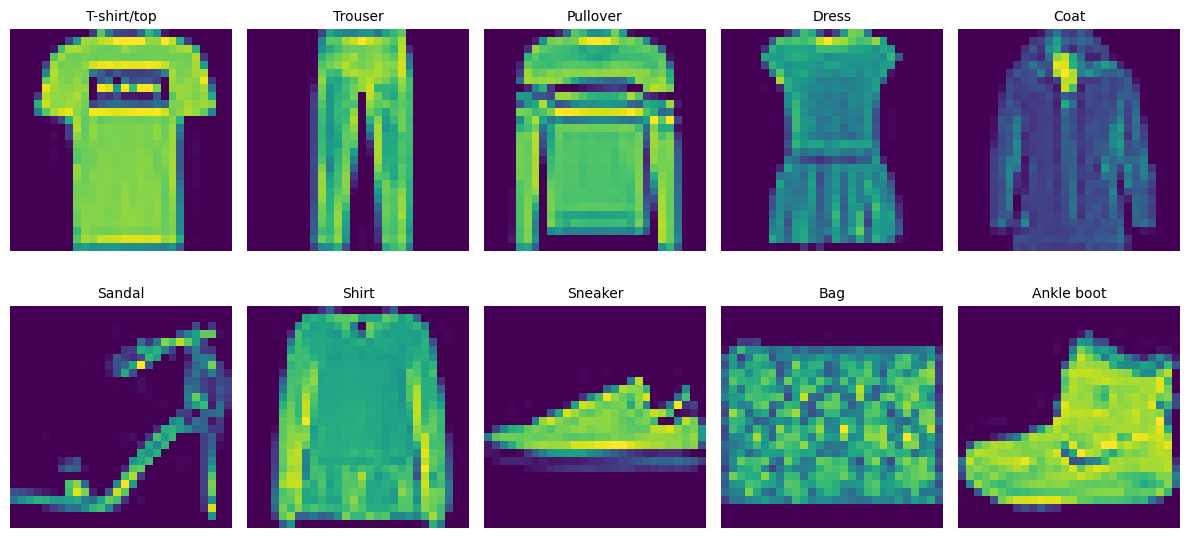

In [47]:
#Visualizing all images to assist in selecting the final choice of models
#dictionary to hold one index per class
class_indices = {}
# finding one example for every class
for index, label in enumerate(train_dataset.targets):
    label_item = label.item() if hasattr(label, 'item') else int(label)
    if label_item not in class_indices:
        class_indices[label_item] = index
    if len(class_indices) == 10:
        break

# 2x5 grid plot
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

# Plot each class example
for i in range(10):
    img_index= class_indices[i]
    img, label = train_dataset[img_index]
    img_array = np.array(img)
    axes[i].imshow(img_array)
#    axes[i].imshow(img_array, cmap='gray')
    axes[i].set_title(train_dataset.classes[i], fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

All correct: 7000 validation images
Only LR correct: 184 validation images
Only decision tree correct: 156 validation images
Only RF correct: 95 validation images
Only SVM correct: 65 validation images
All wrong: 646 validation images


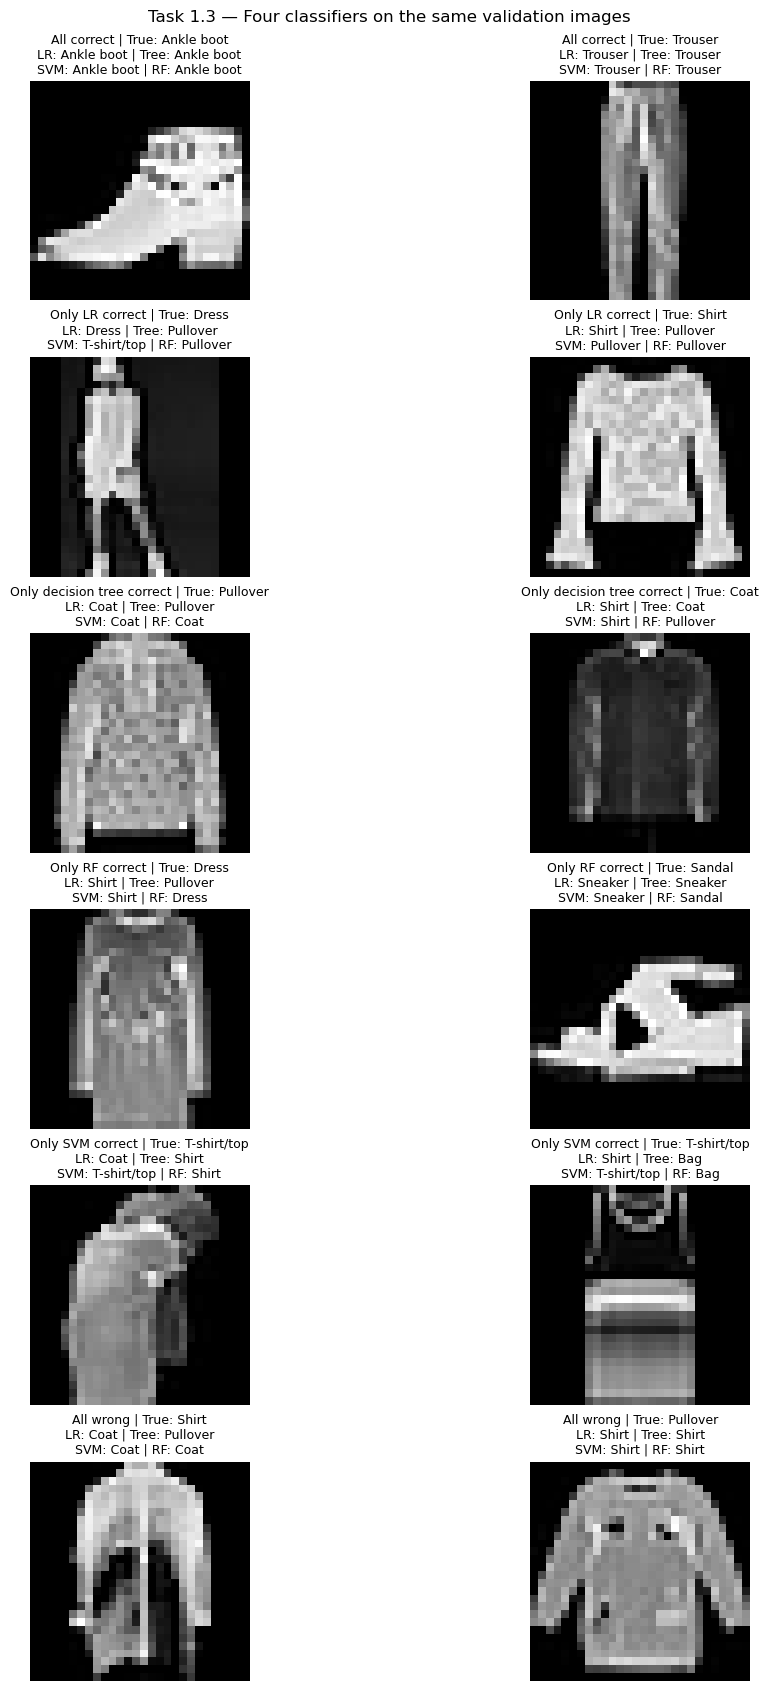

In [45]:
logreg_correct = val_predict_logreg == y_val
dectree_correct = val_predict_dectree == y_val
rf_correct = val_predict_rf == y_val
svm_correct = val_predict_svm == y_val

groups = [
    ("All correct", logreg_correct & dectree_correct & rf_correct & svm_correct),
    ("Only LR correct", logreg_correct & ~dectree_correct & ~rf_correct & ~svm_correct),
    ("Only decision tree correct", ~logreg_correct & dectree_correct & ~rf_correct & ~svm_correct),
    ("Only RF correct", ~logreg_correct & ~dectree_correct & rf_correct & ~svm_correct),
    ("Only SVM correct", ~logreg_correct & ~dectree_correct & ~rf_correct & svm_correct),
    ("All wrong", ~logreg_correct & ~dectree_correct & ~rf_correct & ~svm_correct),
]

rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(groups), 2, figsize=(10, 2.8 * len(groups)), layout="constrained")

for row, (outcome, mask) in enumerate(groups):
    positions = np.flatnonzero(mask)
    chosen = rng.choice(positions, size=min(2, len(positions)), replace=False)
    print(f"{outcome}: {len(positions)} validation images")

    for ax in axes[row]:
        ax.axis("off")

    if len(positions) == 0:
        axes[row, 0].set_title(f"{outcome} | 0 examples")

    for ax, pos in zip(axes[row], chosen):
        #ax.imshow(images[val_index[pos]], vmin=0, vmax=255)
        # (note: TDS said gray scale is better for comparison)
        ax.imshow(images[val_index[pos]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{outcome} | True: {class_names[y_val[pos]]}\n"
            f"LR: {class_names[val_predict_logreg[pos]]} | Tree: {class_names[val_predict_dectree[pos]]}\n"
            f"SVM: {class_names[val_predict_svm[pos]]} | RF: {class_names[val_predict_rf[pos]]}",
            fontsize=9,)

fig.suptitle("Task 1.3 — Four classifiers on the same validation images")
fig.savefig("figures/part1_error_examples_4_classifiers.png", dpi=150, bbox_inches="tight")
plt.show()

.  
**** observations from the above visualizations ***
* Ankle Boot and Trouser are the easiest of all classes for all 4 classifers. Next is Sandal
* Decision Tree predicts Coat better because it focuses on the pixel brightness and Coat images mostly seem to be light on brightness
* Shirt is the hardest for all classes. Shirts seem to be characterized with mostly flat top, raised slightly on the shoulders and mostly longer images. Although there are some variations where they are short.
* Training set accuracy for Random Forest is 100%. Is it probably overfiting.
* Decision tree has the lowest recall, lowest accuracy rate and struggles more with Shirts.
* When hands are longer than the body in a shirt, most classifiers are predicting it as a pullover where only Logistic Regression seems to identigy them correctly as shirt
* When shirts are short or does not have flat surface, Logistic Regression identifies them as T-Shirt/Top while SVM identifies them correctly.
* SVM recognised the most shirts, while logistic regression made fewer of the specific Shirt to T-shirt/top mistakes
*  SVM recognised 30 more shirts overall, even though it called 12 more shirts T-shirt/top. It also made 42 fewer errors involving the other classes
*  Logistic Regression (59.6%) and SVM (62.6%) also had higher Shirt recall than the random forest (56.7%) and decision tree (45.1%).

In [43]:
#starting to pivot towards Logistic Regression and SVM based on above analysis
#so checking when and how SVM predicts correctly
from sklearn.metrics import precision_recall_fscore_support
shirt_id = class_names.index("Shirt")
rows = []

for name, pred in [("Logistic Regression", val_predict_logreg), ("SVM", val_predict_svm)]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val == shirt_id, pred == shirt_id, average="binary", zero_division=0
    )
    false_positives = ((pred == shirt_id) & (y_val != shirt_id)).sum()
    rows.append([name, precision, recall, f1, false_positives])

print(pd.DataFrame(
    rows, columns=["Model", "Shirt precision", "Shirt recall", "Shirt F1", "False positives"]
).round(3).to_string(index=False))

              Model  Shirt precision  Shirt recall  Shirt F1  False positives
Logistic Regression            0.616         0.596     0.606              372
                SVM            0.705         0.626     0.663              262


SVM correctly recognised 32 of these 144 shirts that LR missed.


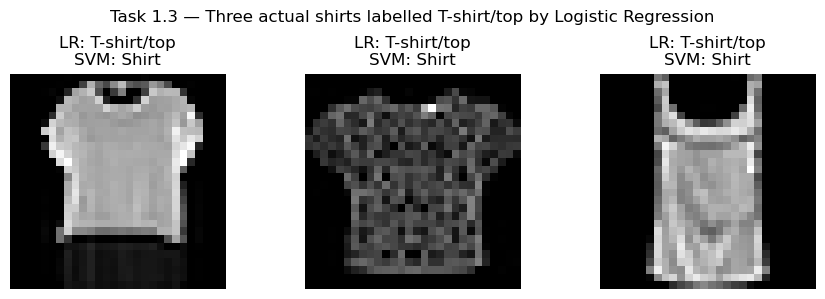

In [46]:
#visualizing to see what features of images SVM predicts correctly
shirt_id = class_names.index("Shirt")
top_id = class_names.index("T-shirt/top")

# Positions in the validation set where LR called a true shirt a T-shirt/top.
positions = np.flatnonzero((y_val == shirt_id) & (val_predict_logreg == top_id))

svm_correct = np.sum(val_predict_svm[positions] == shirt_id)
print(f"SVM correctly recognised {svm_correct} of these {len(positions)} shirts that LR missed.")

svm_positions = np.flatnonzero((y_val == shirt_id) & (val_predict_logreg == top_id) & (val_predict_svm == shirt_id))
chosen = np.random.default_rng(42).choice(svm_positions, size=3, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for ax, pos in zip(axes, chosen):
    ax.imshow(images[val_index[pos]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"LR: T-shirt/top\nSVM: {class_names[val_predict_svm[pos]]}")
    ax.axis("off")

fig.suptitle("Task 1.3 — Three actual shirts labelled T-shirt/top by Logistic Regression")
fig.tight_layout()
fig.savefig("figures/part1_shirt_errors_svm.png", dpi=150, bbox_inches="tight")
plt.show()

1.4 <b>Complexity study</b>. Vary parameters that control model complexity and explain how model complexity affects generalization.

 gamma_factor  gamma  train_accuracy  val_accuracy
         0.25 0.0026          0.8451        0.8389
         1.00 0.0102          0.8989        0.8674
         4.00 0.0410          0.9628        0.8737


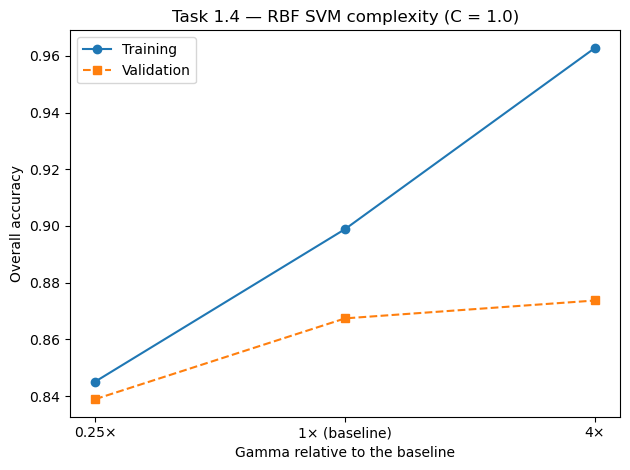

In [47]:
#to-do:
from sklearn.base import clone

gamma_base = 1.0 / (X_fit.shape[1] * X_fit.var(dtype="float64"))
rows = []

for factor in [0.25, 1.0, 4.0]:
    gamma_value = factor * gamma_base
 
    fitted_svm = clone(svm).set_params(gamma=gamma_value)
    fitted_svm.fit(X_fit, y_fit)

    rows.append({
        "gamma_factor": factor,
        "gamma": gamma_value,
        "train_accuracy": fitted_svm.score(X_fit, y_fit),
        "val_accuracy": fitted_svm.score(X_val, y_val),})

gamma_results = pd.DataFrame(rows)
gamma_results.to_csv("results/part1_4_svm_gamma_study.csv", index=False)
print(gamma_results.round(4).to_string(index=False))

ax = gamma_results.plot(x="gamma_factor", y="train_accuracy", marker="o", label="Training")
gamma_results.plot(
    x="gamma_factor", y="val_accuracy", marker="s",
    linestyle="--", label="Validation", ax=ax)
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 1, 4], labels=["0.25×", "1× (baseline)", "4×"])
ax.set_xlabel("Gamma relative to the baseline")
ax.set_ylabel("Overall accuracy")
ax.set_title("Task 1.4 — RBF SVM complexity (C = 1.0)")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_svm_gamma_study.png", dpi=150)
plt.show()

.  
** Observation Notes **
* Going from 0.25× to 1× improved validation accuracy by 2.85 percentage. Going from 1× to 4× added only 0.63 percentage on validation, while training accuracy went up by 6.39%.
* So with still keeping C=1.0 fixed, making the SVM boundary more local helped on validation images.
* The 4× gamma setting performed best on validation at 87.37%.
* This is 0.63% more than baseline. So compared with the baseline, it correctly classified 63 more of the 10,000 validation images
* But the larger gain was on the training set (96.28%)

In [ ]:
svm_selected = fitted_svm

In [52]:
baseline = gamma_results.loc[gamma_results["gamma_factor"] == 1.0].iloc[0]
best = gamma_results.loc[gamma_results["val_accuracy"].idxmax()]
svm_selected = fitted_svm

val_gain_pp = 100 * (best["val_accuracy"] - baseline["val_accuracy"])

result = (
    f"Best of {len(gamma_results)} gamma settings by validation accuracy: "
    f"{best['gamma_factor']:g}× baseline (gamma={best['gamma']:.4f}, C=1.0). "
    f"Training accuracy {best['train_accuracy']:.2%}; "
    f"validation accuracy {best['val_accuracy']:.2%} "
    f"({val_gain_pp:+.2f} percentage points vs baseline)."
)
print(result)

exp_part1_svm_gamma = {
    "id": "P1-4_SVM_GAMMA-01",
    "question": "Does the change in gamma to the more local decision boundary improve validation accuracy, or does the benefit appear mainly on the training set?",
    "hypothesis": "For higher gamma, highest overall accuracy training set and highest overall accuracy  validation set",
    "changed_variable": "gamma = 0.25, 1.0 (scale), 4.0",
    "fixed_conditions": "C=1.0",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "kernel='rbf', C=1.0, gamma=varied, random_state=42",
    "metric": "overall training accuracy, overall validation accuracy",
    "result": {result},
    "output_path": ("results/part1_4_svm_gamma_study.csv; figures/part1_4_svm_gamma_study.png "),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_svm_gamma])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

Best of 3 gamma settings by validation accuracy: 4× baseline (gamma=0.0410, C=1.0). Training accuracy 96.28%; validation accuracy 87.37% (+0.63 percentage points vs baseline).


/opt/conda/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


    C  train_accuracy  val_accuracy   gap
 0.01          0.8416        0.8374  0.42
 0.10          0.8865        0.8506  3.59
 1.00          0.9246        0.8408  8.38
10.00          0.9503        0.8162 13.41


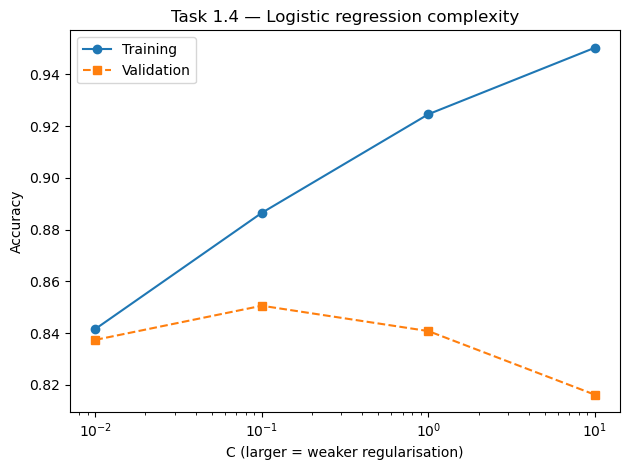

In [55]:
logreg_rows = []
for c_value in [0.01, 0.1, 1.0, 10.0]:
    if c_value == 1.0:
        fitted_logreg = logreg  # reusing the already fitted model earlier (todo: do the same for SVM above later)
    else:
        fitted_logreg = clone(logreg).set_params(C=c_value)
        fitted_logreg.fit(X_fit, y_fit)
    training_accuracy = fitted_logreg.score(X_fit, y_fit)
    validation_accuracy = fitted_logreg.score(X_val, y_val)
    logreg_rows.append({
        "C": c_value,
        "train_accuracy": training_accuracy,
        "val_accuracy": validation_accuracy,
        "gap": 100 * (training_accuracy - validation_accuracy),})

cvalue_results = pd.DataFrame(logreg_rows)
cvalue_results.to_csv("results/part1_4_logreg_cvalue_study.csv", index=False)
print(cvalue_results.round(4).to_string(index=False))

ax = cvalue_results.plot(x="C", y="train_accuracy", marker="o", label="Training", logx=True)
cvalue_results.plot(x="C", y="val_accuracy", marker="s", linestyle="--", label="Validation", ax=ax)
ax.set(xlabel="C (larger = weaker regularisation)", ylabel="Accuracy",
       title="Task 1.4 — Logistic regression complexity")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_logreg_cvalye_study.png", dpi=150)
plt.show()


.  
** Analysis / observation from above **
* 0.1 has the highest validation accuracy of 85.06%
* But one of the fit reached 500 iterations set as max before the stopping condition could be met. It has provided a prediction but I need to rerun with higher limit to see if the outcome changes.

In [56]:
exp_part1_logreg_cvalue = {
    "id": "P1-4_LOGREG_CVALUE-01",
    "question": "Does weaker regularisation overfit the training data at a cost to generalisation?",
    "hypothesis": "Larger C improves training accuracy while validation accuracy falls",
    "changed_variable": "C = 0.01, 0.1, 1.0, 10.0",
    "fixed_conditions": "solver=lbfgs, max_iter=500",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "solver=lbfgs, max_iter=500",
    "metric": "training accuracy, validation accuracy",
    "result": "C=0.1 has the highest validation accuracy of 85.06% but one of the fit reached max iteration",
    "output_path": ("results/part1_4_logreg_cvalue_study.csv; figures/part1_4_logreg_cvalye_study.png"),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg_cvalue])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)

    C  iterations  converged  train_accuracy  val_accuracy   gap
 0.01         177       True          0.8416        0.8374  0.42
 0.10         242       True          0.8865        0.8506  3.59
 1.00         405       True          0.9246        0.8408  8.38
10.00         812       True          0.9556        0.8160 13.96


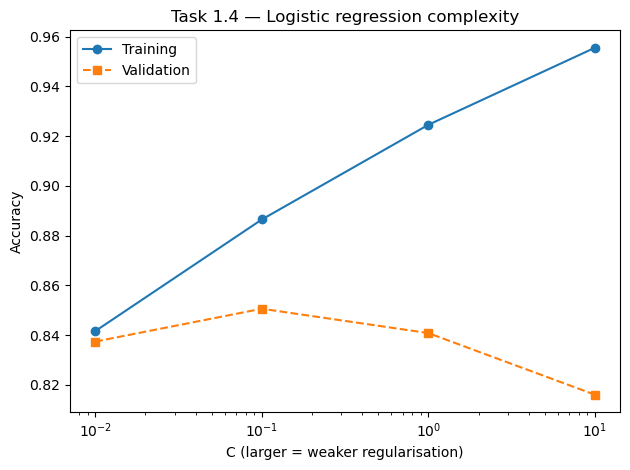

In [57]:
import warnings
from sklearn.exceptions import ConvergenceWarning
logreg_rows = []
logreg_models = {}

for c_value in [0.01, 0.1, 1.0, 10.0]:
    fitted_logreg = clone(logreg).set_params(C=c_value, max_iter=2000)

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        fitted_logreg.fit(X_fit, y_fit)

    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    train_accuracy = fitted_logreg.score(X_fit, y_fit)
    val_accuracy = fitted_logreg.score(X_val, y_val)

    logreg_models[c_value] = fitted_logreg
    logreg_rows.append({
        "C": c_value,
        "iterations": fitted_logreg.n_iter_.max(),
        "converged": converged,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "gap": 100 * (train_accuracy - val_accuracy),})

cvalue_results = pd.DataFrame(logreg_rows)
cvalue_results.to_csv("results/part1_4_logreg_cvalue_iter2000_study.csv", index=False)
print(cvalue_results.round(4).to_string(index=False))

ax = cvalue_results.plot(x="C", y="train_accuracy", marker="o", label="Training", logx=True)
cvalue_results.plot(x="C", y="val_accuracy", marker="s", linestyle="--", label="Validation", ax=ax)
ax.set(xlabel="C (larger = weaker regularisation)", ylabel="Accuracy",
       title="Task 1.4 — Logistic regression complexity")
ax.figure.tight_layout()
ax.figure.savefig("figures/part1_4_logreg_cvalue_iter2000_study.png", dpi=150)
plt.show()



.  
** Observation Notes **
* All four converged this time and still C=0.1 achieved the highest validation accuracy of the four settings: 85.06%.
* The C=10 fit needed 812 iterations and hence caused the warning last time.
* Increasing C from 0.01 to 0.1 improved validation accuracy from 83.74% to 85.06%. Increasing it further to 10 raised training accuracy from 88.65% to 95.56%, while validation accuracy fell to 81.60%.
* This is evidence of overfitting at the higher setting: the model fitted the training images better and made more errors on held-out images

In [60]:
best_logreg_row = cvalue_results.loc[cvalue_results["val_accuracy"].idxmax()]
logreg_selected = logreg_models[best_logreg_row["C"]]

exp_part1_logreg_cvalue_2 = {
    "id": "P1-4_LOGREG_CVALUE-02",
    "question": "Does increasing the max iteration converge all the C value fits?",
    "hypothesis": "All C fits coverage to identify the best C value",
    "changed_variable": "C = 0.01, 0.1, 1.0, 10.0 and max_iter=2000",
    "fixed_conditions": "solver=lbfgs",
    "split": f"Training {len(train_index)}, Fitting {len(fit_index)}, Validation {len(val_index)}",
    "seed": f"Test={TEST_SEED}, Fit={FIT_SEED}, Clustering={CLUSTER_SEED}",
    "configuration": "solver=lbfgs",
    "metric": "training accuracy, validation accuracy",
    "result": "All four fits converged. But C=0.1 still has the highest validation accuracy of 85.06%",
    "output_path": ("results/part1_4_logreg_cvalue_iter2000_study.csv; figures/part1_4_logreg_cvalue_iter2000_study.png.png"),
}
register = pd.read_csv(register_path) if register_path.exists() else pd.DataFrame()
register = pd.concat([register, pd.DataFrame([exp_part1_logreg_cvalue_2])], ignore_index=True)
register = register.drop_duplicates(subset="id", keep="last")
register.to_csv(register_path, index=False)


1.5 <b>Decisions and costs </b> Define a binary decision problem of your own, derived from the ten classes. Using validation data, show how the decision threshold trades one error against the other.

In [ ]:
#to-do: